# 03 · Regression models: the coefficient ladder (RQ2, RQ4)
**Study Smarter, Not Harder** · Member C (Modeller) · slides 4-5 · Portuguese course file.

All models are OLS with **HC3 heteroskedasticity-robust standard errors** and 95% CIs. Every model in the
ladder is fitted on the same rows (no missing values, so n = 649 for "all" and n = 634 for "G3 > 0").

**Model numbering differs from the readme.** The readme pilot has three rungs (M1 raw, M2 + all controls,
M3 + G1/G2). Here the controls are split into two rungs so the audience can see where the drop happens:

| Here | Adds | Readme pilot name |
|---|---|---|
| M1 | study time only | M1 raw |
| M2 | academic and demographic controls: failures, log(absences+1), sex, age, school, address, wants higher education | (new) |
| M3 | family/social/support: Medu, Fedu, goout, Dalc, Walc, freetime, health, internet, schoolsup, famsup, paid, romantic | M2 + controls (identical formula) |
| M4 | G1 and G2 | M3 + G1, G2 |

> **Flags for the team (details in sections 2, 5 and 8):** every pilot number is reproduced (section 9), but
> (1) log(absences+1) is only the best functional form once the zero-grade cases are removed; with zero-grade cases, linear fits
> best by AIC; (2) with study time as dummies, the M3 joint test is not significant without zero-grade cases (p = 0.063);
> (3) the Student A vs B profile prediction is driven by the school-support dummy (reverse causality), and
> A comes out *higher* than B unless support is held equal.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
PROC, FIG, RES = Path("../data/processed"), Path("../figures"), Path("../results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a94"
sns.set_theme(style="whitegrid", context="talk", rc={"grid.color": "#e6e6e3", "axes.edgecolor": "#bdbdb8",
                                                      "figure.dpi": 100, "savefig.dpi": 200})
ST_LABELS = {1: "<2 h", 2: "2-5 h", 3: "5-10 h", 4: ">10 h"}
pd.set_option("display.width", 160)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved figures/" + name + ".png")

df = pd.read_csv(PROC / "student-por_clean.csv")
nz = df[~df.zero_grade].copy()
SAMPLES = {"all": df, "G3>0": nz}

ACAD = "failures + log_abs + C(sex) + age + C(school) + C(address) + C(higher)"
FAMSOC = ("Medu + Fedu + goout + Dalc + Walc + freetime + health + C(internet) + C(schoolsup) + C(famsup)"
          " + C(paid) + C(romantic)")
CTRL = ACAD + " + " + FAMSOC                       # = readme CTRL (same 19 variables)
RUNGS = {"M1 study time": "", "M2 + academic/demographic": " + " + ACAD,
         "M3 + family/social": " + " + CTRL, "M4 + G1, G2": " + " + CTRL + " + G1 + G2"}

def fit(formula, d):
    return smf.ols(formula, d).fit(cov_type="HC3")

OUT = []   # long table -> results/regression_comparison.csv
def keep(section, model, sample, m, terms):
    ci = m.conf_int()
    for t in terms:
        OUT.append(dict(section=section, model=model, sample=sample, term=t, estimate=m.params[t], se_hc3=m.bse[t],
                        ci_lo=ci.loc[t, 0], ci_hi=ci.loc[t, 1], p_value=m.pvalues[t], r2=m.rsquared,
                        adj_r2=m.rsquared_adj, aic=m.aic, n=int(m.nobs)))
print(df.shape, nz.shape)

(649, 35) (634, 35)


## 1. The coefficient ladder: study time as a linear (numeric 1-4) term
H0 at each rung: β_studytime = 0 given the other regressors; H1: β_studytime ≠ 0. The coefficient is the
expected change in G3 per one-category step up the study-time scale.

In [2]:
ladder, MODELS = [], {}
for sample, d in SAMPLES.items():
    for name, rhs in RUNGS.items():
        m = fit("G3 ~ studytime" + rhs, d)
        MODELS[(name, sample, "numeric")] = m
        lo, hi = m.conf_int().loc["studytime"]
        ladder.append(dict(model=name, sample=sample, b=m.params["studytime"], lo=lo, hi=hi,
                           p=m.pvalues["studytime"], r2=m.rsquared, adj_r2=m.rsquared_adj, n=int(m.nobs), k=int(m.df_model)))
        keep("ladder (numeric studytime)", name, sample, m, ["studytime"] + (["log_abs"] if "log_abs" in m.params else []))
ladder = pd.DataFrame(ladder)
ladder.round(3)

,model,sample,b,lo,hi,p,r2,adj_r2,n,k
0,M1 study time,all,0.973,0.691,1.255,0.000,0.062,0.061,649,1
1,M2 + academic/demographic,all,0.447,0.195,0.698,0.000,0.287,0.278,649,8
2,M3 + family/social,all,0.415,0.167,0.664,0.001,0.338,0.317,649,20
3,"M4 + G1, G2",all,0.053,-0.049,0.156,0.307,0.856,0.851,649,22
4,M1 study time,G3>0,0.795,0.542,1.049,0.000,0.060,0.059,634,1
5,M2 + academic/demographic,G3>0,0.334,0.101,0.568,0.005,0.302,0.293,634,8
6,M3 + family/social,G3>0,0.310,0.078,0.543,0.009,0.369,0.348,634,20
7,"M4 + G1, G2",G3>0,0.014,-0.072,0.101,0.747,0.888,0.884,634,22


In [3]:
for sample in SAMPLES:
    L = ladder[ladder["sample"] == sample].set_index("model")
    b1 = L["b"].iloc[0]
    print(sample, " | ".join(f"{k.split()[0]}: {v:+.2f} ({v / b1:.0%} of M1)" for k, v in L["b"].items()))

all M1: +0.97 (100% of M1) | M2: +0.45 (46% of M1) | M3: +0.42 (43% of M1) | M4: +0.05 (5% of M1)
G3>0 M1: +0.80 (100% of M1) | M2: +0.33 (42% of M1) | M3: +0.31 (39% of M1) | M4: +0.01 (2% of M1)


**Interpretation:** Each rung tests H0: β_studytime = 0. Raw (M1), each step up the study-time scale goes with +0.97 G3 points (95% CI 0.69-1.25, R² = 0.06). **Most of the shrinkage happens at M2**: adding failures, absences, sex, age, school, address and university ambition cuts it to +0.45 (0.20-0.70), 46% of the raw value. The family/social block in M3 barely moves it (+0.42, 0.17-0.66, p = 0.001; adj R² 0.32), so it is academic history and ambition, not family background or social life, that explains the raw gap. Adding G1 and G2 (M4) wipes it out: +0.05 (-0.05 to 0.16, p = 0.31), fail to reject H0, while adj R² jumps to 0.85. Without zero-grade cases: 0.80 → 0.33 → 0.31 → 0.01, the same story. All four models use the same 649 (or 634) students, so the drop is not caused by changing samples. Pilot values (readme M1/M2/M3 = M1/M3/M4 here) reproduced.

## 2. The same ladder with study time as dummies (reference: <2 h)
Study time is an ordinal category, not hours, and the raw means plateau after 5-10 h, so the linear term may
be the wrong shape. Each dummy = expected G3 difference from the <2 h group. Joint Wald test (HC3):
H0: all three dummies = 0.

In [4]:
DUM = ["C(studytime)[T.2]", "C(studytime)[T.3]", "C(studytime)[T.4]"]
rows = []
for sample, d in SAMPLES.items():
    for name, rhs in RUNGS.items():
        m = fit("G3 ~ C(studytime)" + rhs, d)
        MODELS[(name, sample, "dummies")] = m
        w = m.wald_test(" , ".join(f"{t} = 0" for t in DUM), scalar=True)
        ci = m.conf_int()
        rows.append({"model": name, "sample": sample,
                     **{ST_LABELS[i + 2]: f"{m.params[t]:+.2f} [{ci.loc[t, 0]:+.2f}, {ci.loc[t, 1]:+.2f}]"
                        for i, t in enumerate(DUM)},
                     "joint F": round(float(w.statistic), 2), "joint p": float(w.pvalue), "adj R2": round(m.rsquared_adj, 3)})
        keep("ladder (studytime dummies)", name, sample, m, DUM)
pd.DataFrame(rows)

,model,sample,2-5 h,5-10 h,>10 h,joint F,joint p,adj R2
0,M1 study time,all,"+1.25 [+0.68, +1.81]","+2.38 [+1.72, +3.05]","+2.21 [+1.10, +3.32]",54.59,8.391312e-12,0.064
1,M2 + academic/demographic,all,"+0.36 [-0.16, +0.89]","+1.13 [+0.50, +1.76]","+1.05 [+0.08, +2.02]",14.92,1.885282e-03,0.277
2,M3 + family/social,all,"+0.31 [-0.22, +0.84]","+1.01 [+0.39, +1.64]","+1.01 [+0.07, +1.96]",12.93,4.791166e-03,0.316
3,"M4 + G1, G2",all,"+0.16 [-0.10, +0.42]","+0.16 [-0.11, +0.44]","+0.09 [-0.24, +0.41]",1.72,6.331917e-01,0.851
4,M1 study time,G3>0,"+1.11 [+0.65, +1.56]","+1.96 [+1.35, +2.56]","+1.79 [+0.71, +2.86]",49.33,1.108638e-10,0.064
5,M2 + academic/demographic,G3>0,"+0.32 [-0.12, +0.75]","+0.79 [+0.21, +1.36]","+0.85 [-0.09, +1.79]",8.80,3.202880e-02,0.291
6,M3 + family/social,G3>0,"+0.31 [-0.13, +0.75]","+0.68 [+0.12, +1.24]","+0.86 [-0.06, +1.78]",7.31,6.257347e-02,0.346
7,"M4 + G1, G2",G3>0,"+0.11 [-0.09, +0.31]","+0.05 [-0.18, +0.28]","+0.02 [-0.26, +0.29]",1.42,7.005933e-01,0.884


**Interpretation:** With dummies, the raw gaps (+1.25, +2.38, +2.21 vs <2 h) match the group means exactly. In M3 the 2-5 h dummy is not significant (+0.31, CI -0.22 to +0.84); only 5-10 h (+1.01) and >10 h (+1.01) clear zero, and the joint test rejects H0 (p = 0.005). **Caution not in the pilot: without zero-grade cases the M3 joint test is only p = 0.063** (not significant at 5%), even though the linear version gives p = 0.009. The linear term borrows strength by assuming equal steps, so the "study time still matters after controls" claim is a bit coding-dependent on the G3 > 0 sample. With G1/G2 (M4) all dummies are tiny and jointly non-significant (p = 0.63 / 0.70) in both samples. The >10 h estimate never exceeds 5-10 h, consistent with the plateau.

## 3. Figure: the coefficient ladder

saved figures/08_coefficient_ladder.png


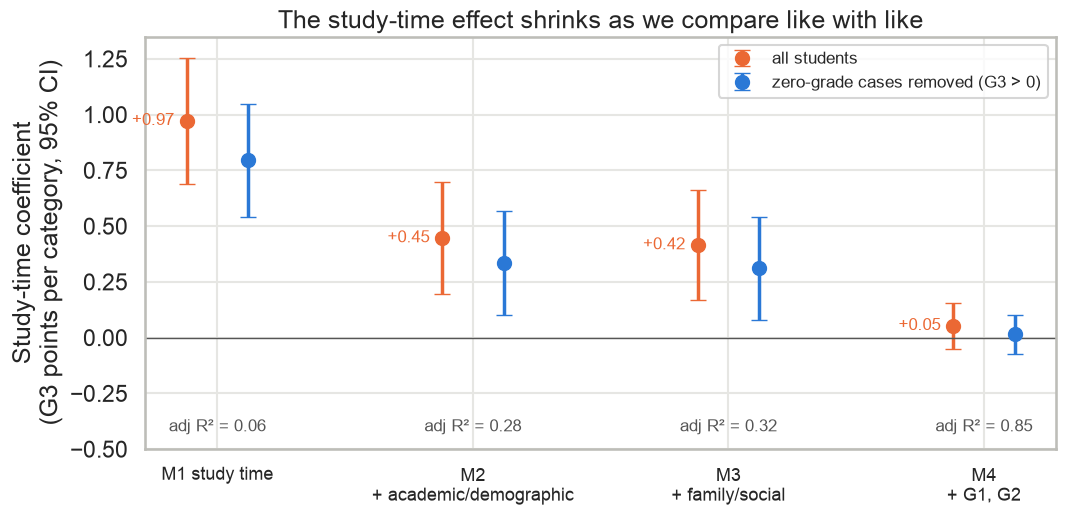

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(RUNGS))
for off, (sample, c) in zip([-0.12, 0.12], [("all", ORANGE), ("G3>0", BLUE)]):
    L = ladder[ladder["sample"] == sample]
    ax.errorbar(x + off, L.b, yerr=[L.b - L.lo, L.hi - L.b], fmt="o", color=c, ms=10, lw=2.5, capsize=6,
                label=f"{'all students' if sample == 'all' else 'zero-grade cases removed (G3 > 0)'}")
    for xi, (b, r2) in enumerate(zip(L.b, L.adj_r2)):
        if sample == "all":
            ax.text(xi - 0.17, b, f"{b:+.2f}", ha="right", va="center", fontsize=12, color=c)
            ax.text(xi, -0.42, f"adj R² = {r2:.2f}", ha="center", fontsize=12, color="#555")
ax.axhline(0, color="#555", lw=1)
ax.set_xticks(x, [n.replace(" + ", "\n+ ") for n in RUNGS], fontsize=13)
ax.set(ylabel="Study-time coefficient\n(G3 points per category, 95% CI)", ylim=(-0.5, 1.35),
       title="The study-time effect shrinks as we compare like with like")
ax.legend(fontsize=12, loc="upper right")
savefig(fig, "08_coefficient_ladder")

## 4. What the controls do: M3 coefficients (the "suspect line-up")
M3 = the readme's "M2 + controls" model. Coefficient plot with HC3 95% CIs, both samples.

In [6]:
m3a, m3n = MODELS[("M3 + family/social", "all", "numeric")], MODELS[("M3 + family/social", "G3>0", "numeric")]
coefs = pd.DataFrame({"all b": m3a.params, "all lo": m3a.conf_int()[0], "all hi": m3a.conf_int()[1], "all p": m3a.pvalues,
                      "G3>0 b": m3n.params, "G3>0 lo": m3n.conf_int()[0], "G3>0 hi": m3n.conf_int()[1],
                      "G3>0 p": m3n.pvalues}).drop("Intercept")
keep("M3 full coefficients", "M3 + family/social", "all", m3a, list(coefs.index))
keep("M3 full coefficients", "M3 + family/social", "G3>0", m3n, list(coefs.index))
coefs.sort_values("all b").round(3)

,all b,all lo,all hi,all p,G3>0 b,G3>0 lo,G3>0 hi,G3>0 p
failures,-1.421,-1.838,-1.004,0.000,-1.233,-1.552,-0.913,0.000
C(schoolsup)[T.yes],-1.325,-2.029,-0.622,0.000,-1.165,-1.686,-0.644,0.000
C(school)[T.MS],-1.311,-1.866,-0.756,0.000,-0.873,-1.333,-0.413,0.000
C(paid)[T.yes],-0.497,-1.300,0.306,0.225,-0.537,-1.179,0.105,0.101
C(sex)[T.M],-0.481,-0.982,0.020,0.060,-0.452,-0.861,-0.043,0.030
C(romantic)[T.yes],-0.433,-0.899,0.033,0.068,-0.266,-0.643,0.112,0.168
Dalc,-0.250,-0.632,0.132,0.200,-0.191,-0.462,0.080,0.167
health,-0.167,-0.315,-0.019,0.027,-0.128,-0.254,-0.002,0.046
log_abs,-0.149,-0.394,0.095,0.231,-0.448,-0.652,-0.244,0.000
Walc,-0.109,-0.339,0.122,0.356,-0.074,-0.257,0.110,0.431


saved figures/09_coefficient_plot_m3.png


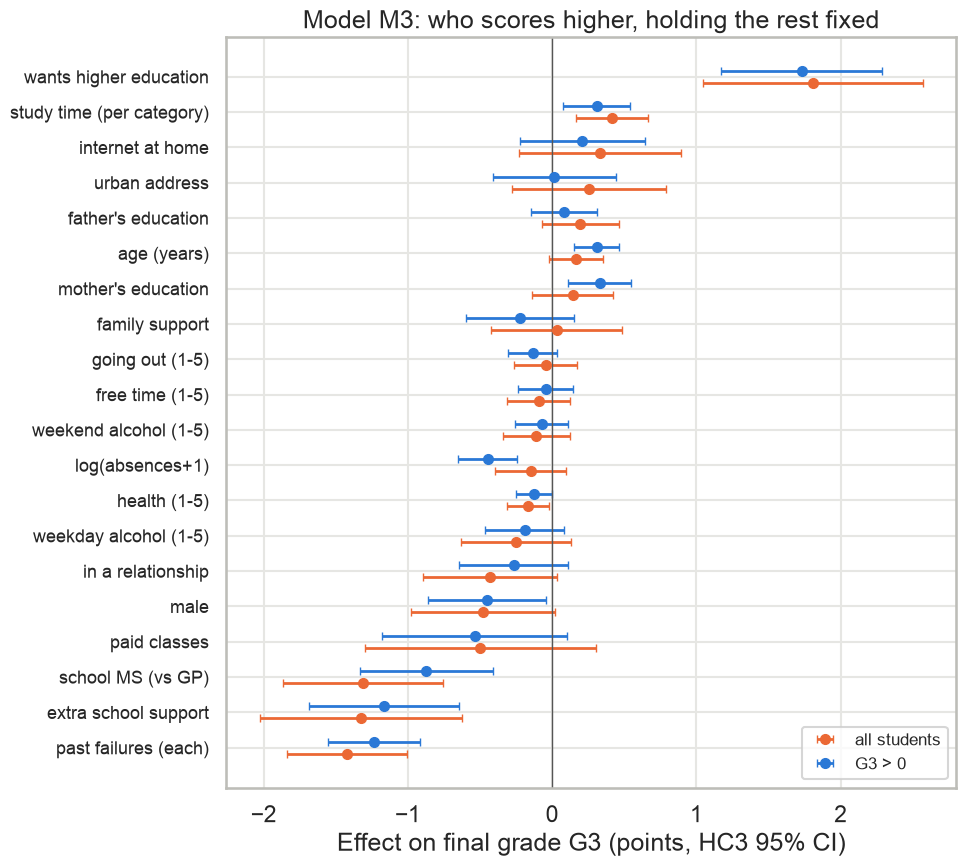

In [7]:
PRETTY = {"C(higher)[T.yes]": "wants higher education", "C(school)[T.MS]": "school MS (vs GP)",
          "C(schoolsup)[T.yes]": "extra school support", "C(sex)[T.M]": "male", "C(address)[T.U]": "urban address",
          "C(internet)[T.yes]": "internet at home", "C(famsup)[T.yes]": "family support", "C(paid)[T.yes]": "paid classes",
          "C(romantic)[T.yes]": "in a relationship", "log_abs": "log(absences+1)", "studytime": "study time (per category)",
          "failures": "past failures (each)", "Medu": "mother's education", "Fedu": "father's education",
          "goout": "going out (1-5)", "Dalc": "weekday alcohol (1-5)", "Walc": "weekend alcohol (1-5)",
          "freetime": "free time (1-5)", "health": "health (1-5)", "age": "age (years)"}
c = coefs.sort_values("all b")
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(c))
for off, s, col in [(-0.17, "all", ORANGE), (0.17, "G3>0", BLUE)]:
    ax.errorbar(c[f"{s} b"], y + off, xerr=[c[f"{s} b"] - c[f"{s} lo"], c[f"{s} hi"] - c[f"{s} b"]], fmt="o",
                color=col, ms=7, lw=2, capsize=3, label="all students" if s == "all" else "G3 > 0")
ax.axvline(0, color="#555", lw=1)
ax.set_yticks(y, [PRETTY.get(t, t) for t in c.index], fontsize=13)
ax.set(xlabel="Effect on final grade G3 (points, HC3 95% CI)", title="Model M3: who scores higher, holding the rest fixed")
ax.legend(fontsize=12, loc="lower right")
savefig(fig, "09_coefficient_plot_m3")

**Interpretation:** Holding everything else fixed (all students), the biggest associations are: wanting higher education +1.81 (1.04-2.57), each past failure -1.42 (-1.84 to -1.00), being at MS -1.31, and receiving extra school support -1.33 (support goes to weaker students: reverse causality, not harm). Study time is +0.42 per category, smaller than any of these. Sex (male -0.48, p = 0.060), alcohol, going out, internet and family support are not significant. The zero-grade cases change two things: log(absences+1) goes from -0.15 (p = 0.23) to -0.45 (p < 0.001), and mother's education (+0.33, p = 0.003) and age (+0.31, p < 0.001) become significant, while the MS penalty shrinks from -1.31 to -0.87 (because 14 of the 15 zero-grade cases are at MS).

## 5. Functional form for absences: linear vs log(absences+1) vs quadratic
Each version is fitted as a simple regression and inside M3 (all other regressors identical). Compare adjusted
R² and AIC (lower is better) and check the sign/significance. H0 for the quadratic: β(absences²) = 0.

In [8]:
BASE = "G3 ~ studytime + " + CTRL.replace("log_abs + ", "")
FORMS = {"linear": "absences", "log(abs+1)": "log_abs", "quadratic": "absences + I(absences ** 2)"}
rows = []
for sample, d in SAMPLES.items():
    for ctx, base in [("simple", "G3 ~ "), ("in M3", BASE + " + ")]:
        for fname, term in FORMS.items():
            m = fit(base + term, d)
            terms = [t for t in m.params.index if "absences" in t or t == "log_abs"]
            keep(f"functional form ({ctx})", fname, sample, m, terms)
            rows.append({"sample": sample, "context": ctx, "form": fname, "adj R2": m.rsquared_adj, "AIC": m.aic,
                         **{t: f"{m.params[t]:+.4f} (p={m.pvalues[t]:.3f})" for t in terms}})
ff = pd.DataFrame(rows)
ff["dAIC vs best"] = ff["AIC"] - ff.groupby(["sample", "context"])["AIC"].transform("min")
ff.round(4)

,sample,context,form,adj R2,AIC,absences,log_abs,I(absences ** 2),dAIC vs best
0,all,simple,linear,0.0068,3361.4850,-0.0636 (p=0.022),NaN,NaN,0.0000
1,all,simple,log(abs+1),0.0038,3363.4255,NaN,-0.2458 (p=0.078),NaN,1.9406
2,all,simple,quadratic,0.0057,3363.1937,-0.0912 (p=0.171),NaN,+0.0017 (p=0.677),1.7088
3,all,in M3,linear,0.3180,3136.1784,-0.0418 (p=0.105),NaN,NaN,0.0000
4,all,in M3,log(abs+1),0.3166,3137.4945,NaN,-0.1494 (p=0.231),NaN,1.3161
5,all,in M3,quadratic,0.3169,3138.1635,-0.0470 (p=0.392),NaN,+0.0003 (p=0.923),1.9851
6,G3>0,simple,linear,0.0369,3032.9668,-0.1132 (p=0.000),NaN,NaN,4.3138
7,G3>0,simple,log(abs+1),0.0434,3028.6530,NaN,-0.5940 (p=0.000),NaN,0.0000
8,G3>0,simple,quadratic,0.0446,3028.9109,-0.2173 (p=0.000),NaN,+0.0062 (p=0.051),0.2578
9,G3>0,in M3,linear,0.3432,2808.9855,-0.0838 (p=0.001),NaN,NaN,4.7869


In [9]:
# Implied effect of going from 0 to 10 absences (the 90th percentile) under each form, in M3
for sample, d in SAMPLES.items():
    out = []
    for fname, term in FORMS.items():
        m = fit(BASE + " + " + term, d)
        if fname == "linear":       eff = 10 * m.params["absences"]
        elif fname == "log(abs+1)": eff = np.log(11) * m.params["log_abs"]
        else:                       eff = 10 * m.params["absences"] + 100 * m.params["I(absences ** 2)"]
        out.append(f"{fname}: {eff:+.2f}")
    print(f"{sample:5s} 0 -> 10 absences: " + " | ".join(out))

all   0 -> 10 absences: linear: -0.42 | log(abs+1): -0.36 | quadratic: -0.44
G3>0  0 -> 10 absences: linear: -0.84 | log(abs+1): -1.07 | quadratic: -1.14


**Interpretation:** **Flag: this partly disagrees with the readme's reasoning on slide 7** ("absences enter as log(abs+1) because the effect is concave"). With the zero-grade cases included, the plain linear term has the lowest AIC (simple and in M3), and no form of absences is significant in M3 (linear p = 0.105, log p = 0.231, quadratic terms p = 0.39/0.92). Only **without zero-grade cases** does log(abs+1) win (lowest AIC, ΔAIC = 4.8 vs linear in M3; log_abs -0.45, p < 0.001). The quadratic term is positive (concave decline that flattens out) but not significant (p = 0.051 simple, p = 0.103 in M3). So: log is the better form on the cleaned sample, but the evidence for curvature is modest; the substantive result (0 → 10 absences costs about 1 point without zero-grade cases: -0.84 linear, -1.07 log, -1.14 quadratic; about -0.4 with zero-grade cases) is the same under all three forms. Suggested slide wording: "log fits best once the zero-grade cases are removed; linear and quadratic give the same answer."

## 6. Interaction: does study time pay off differently for students with past failures? (backup)
H0: β(studytime × failures) = 0. Two specifications: the pilot's lean one (log_abs, sex, school) and the full
M3 controls. Fitted with and without zero-grade cases. Note that only a few students have 2+ failures.

In [10]:
print("failures distribution:", df.failures.value_counts().sort_index().to_dict())
print(pd.crosstab(df.studytime.map(ST_LABELS), df.failures, margins=True))
rows = []
for spec, rhs in [("lean (pilot)", " + log_abs + C(sex) + C(school)"), ("full M3 controls", " + " + CTRL.replace("failures + ", ""))]:
    for sample, d in SAMPLES.items():
        m = fit("G3 ~ studytime * failures" + rhs, d)
        keep(f"interaction ({spec})", "studytime x failures", sample, m, ["studytime", "failures", "studytime:failures"])
        ci = m.conf_int().loc["studytime:failures"]
        rows.append({"spec": spec, "sample": sample, "n": int(m.nobs),
                     "studytime": round(m.params["studytime"], 3), "failures": round(m.params["failures"], 3),
                     "studytime:failures": round(m.params["studytime:failures"], 3),
                     "CI": f"[{ci[0]:+.2f}, {ci[1]:+.2f}]", "p": round(m.pvalues["studytime:failures"], 3)})
pd.DataFrame(rows)

failures distribution: {0: 549, 1: 70, 2: 16, 3: 14}
failures     0   1   2   3  All
studytime                      
2-5 h      264  26  10   5  305
5-10 h      89   6   2   0   97
<2 h       163  36   4   9  212
>10 h       33   2   0   0   35
All        549  70  16  14  649


,spec,sample,n,studytime,failures,studytime:failures,CI,p
0,lean (pilot),all,649,0.584,-1.496,-0.199,"[-0.81, +0.41]",0.523
1,lean (pilot),G3>0,634,0.521,-0.663,-0.521,"[-0.97, -0.08]",0.022
2,full M3 controls,all,649,0.448,-1.080,-0.218,"[-0.80, +0.36]",0.461
3,full M3 controls,G3>0,634,0.386,-0.398,-0.535,"[-0.97, -0.10]",0.015


**Interpretation:** H0: the payoff to study time does not depend on past failures. On all students, fail to reject (lean: -0.20, p = 0.52; full controls: -0.22, p = 0.46). Without zero-grade cases, reject (lean: -0.52, CI -0.97 to -0.08, p = 0.022; full: -0.54, p = 0.015), i.e. the study-time slope is about half a point smaller per past failure. This reproduces the pilot and is **fragile**: it flips with the 15 zero-grade rows, and only 30 students have 2+ failures (none of them in >10 h with 2+). The sign is also open to two readings (failing students get less out of studying, or students who are struggling study more because they are struggling). Keep it as a backup slide only.

## 7. Which matters more: study time, absences or failures?
Two comparisons from M3 (numeric study time, log absences), both with HC3 95% CIs:
1. **Standardised coefficients** (β × SD(x) / SD(G3)): effect of a one-SD change, in SDs of G3.
2. **Predicted differences for realistic contrasts**: study time <2 h → 5-10 h (2 steps), absences 0 → 10
   (the 90th percentile), failures 0 → 1.

In [11]:
rows = []
for sample, d in SAMPLES.items():
    m = MODELS[("M3 + family/social", sample, "numeric")]
    sy = d.G3.std()
    for var, label, contrast in [("studytime", "study time <2 h -> 5-10 h", 2.0),
                                 ("log_abs", "absences 0 -> 10", np.log(11)),
                                 ("failures", "failures 0 -> 1", 1.0)]:
        sd = d[var].std()
        ci = m.conf_int().loc[var]
        rows.append({"sample": sample, "variable": var, "std beta": m.params[var] * sd / sy,
                     "std lo": ci[0] * sd / sy, "std hi": ci[1] * sd / sy, "contrast": label,
                     "pred diff": m.params[var] * contrast, "pd lo": ci[0] * contrast, "pd hi": ci[1] * contrast,
                     "p": m.pvalues[var]})
        OUT.append(dict(section="standardised / predicted difference", model="M3 + family/social", sample=sample,
                        term=f"{var}: {label}", estimate=m.params[var] * contrast, ci_lo=ci[0] * contrast,
                        ci_hi=ci[1] * contrast, p_value=m.pvalues[var], n=int(m.nobs),
                        se_hc3=m.bse[var] * contrast, r2=m.rsquared, adj_r2=m.rsquared_adj, aic=m.aic))
cmp_ = pd.DataFrame(rows)
cmp_.round(3)

,sample,variable,std beta,std lo,std hi,contrast,pred diff,pd lo,pd hi,p
0,all,studytime,0.107,0.043,0.170,study time <2 h -> 5-10 h,0.831,0.334,1.327,0.001
1,all,log_abs,-0.045,-0.118,0.028,absences 0 -> 10,-0.358,-0.945,0.228,0.231
2,all,failures,-0.261,-0.337,-0.184,failures 0 -> 1,-1.421,-1.838,-1.004,0.000
3,G3>0,studytime,0.096,0.024,0.168,study time <2 h -> 5-10 h,0.621,0.156,1.085,0.009
4,G3>0,log_abs,-0.160,-0.233,-0.087,absences 0 -> 10,-1.075,-1.564,-0.585,0.000
5,G3>0,failures,-0.265,-0.334,-0.197,failures 0 -> 1,-1.233,-1.552,-0.913,0.000


**Interpretation:** Per one standard deviation, past failures matter most (standardised β = -0.26, all and G3 > 0). Study time is about 0.10 SD, and absences are -0.05 (n.s.) with zero-grade cases but -0.16 without. In grade points, for realistic contrasts (M3): moving from <2 h to 5-10 h study is worth +0.83 (0.33-1.33) [+0.62 without zero-grade cases]; one past failure costs -1.42 (-1.84 to -1.00) [-1.23]; going from 0 to 10 absences costs -0.36 (-0.95 to +0.23, n.s.) with zero-grade cases but **-1.08 (-1.56 to -0.59) without**. Once the zero-grade cases are removed, showing up and studying more are in the same league (about 0.6-1.1 points each), and a single past failure outweighs either.

## 8. Two illustrative students: predicted final grade with prediction intervals
Model: M3 with study time as **dummies** (so >10 h gets its own estimate rather than an extrapolated line).
Everything not listed is held at the sample's typical value (median for numeric, most common level for
categories), identical for both students.

| | Student A | Student B |
|---|---|---|
| Study time | >10 h (category 4) | 2-5 h (category 2) |
| Absences | 12 (95th percentile) | 2 (median) |
| Past failures | 1 | 0 |
| Extra school support | no | yes |

95% CI = uncertainty about the *average* student with that profile; 95% prediction interval (PI) = range for
*one* such student.

In [12]:
typical = {}
for col in CTRL.replace("C(", "").replace(")", "").replace(" ", "").split("+"):
    col = "absences" if col == "log_abs" else col
    typical[col] = df[col].mode()[0] if df[col].dtype == object else df[col].median()
PROFILES = {"Student A": dict(typical, studytime=4, absences=12, failures=1, schoolsup="no"),
            "Student B": dict(typical, studytime=2, absences=2, failures=0, schoolsup="yes")}
prof = pd.DataFrame(PROFILES).T
prof["log_abs"] = np.log1p(prof.absences.astype(float))
for c_ in prof.columns:
    if c_ not in ["school", "sex", "address", "higher", "internet", "schoolsup", "famsup", "paid", "romantic"]:
        prof[c_] = prof[c_].astype(float)
print("held fixed:", {k: v for k, v in typical.items() if k not in ["studytime", "absences", "failures", "schoolsup"]})

pred_rows = []
for sample in SAMPLES:
    for mname in ["M3 + family/social", "M2 + academic/demographic"]:
        m = MODELS[(mname, sample, "dummies")]
        sf = m.get_prediction(prof).summary_frame(alpha=0.05)
        sf.index = prof.index
        for who, r in sf.iterrows():
            pred_rows.append(dict(model=mname, sample=sample, student=who, pred=r["mean"], ci_lo=r.mean_ci_lower,
                                  ci_hi=r.mean_ci_upper, pi_lo=r.obs_ci_lower, pi_hi=r.obs_ci_upper))
            OUT.append(dict(section="profile prediction", model=mname, sample=sample, term=who, estimate=r["mean"],
                            ci_lo=r.mean_ci_lower, ci_hi=r.mean_ci_upper, n=int(m.nobs), r2=m.rsquared,
                            adj_r2=m.rsquared_adj, aic=m.aic, se_hc3=r.mean_se,
                            pi_lo=r.obs_ci_lower, pi_hi=r.obs_ci_upper))
preds = pd.DataFrame(pred_rows)
preds.round(2)

held fixed: {'sex': 'F', 'age': np.float64(17.0), 'school': 'GP', 'address': 'U', 'higher': 'yes', 'Medu': np.float64(2.0), 'Fedu': np.float64(2.0), 'goout': np.float64(3.0), 'Dalc': np.float64(1.0), 'Walc': np.float64(2.0), 'freetime': np.float64(3.0), 'health': np.float64(4.0), 'internet': 'yes', 'famsup': 'yes', 'paid': 'no', 'romantic': 'no'}


,model,sample,student,pred,ci_lo,ci_hi,pi_lo,pi_hi
0,M3 + family/social,all,Student A,12.60,11.52,13.68,7.25,17.95
1,M3 + family/social,all,Student B,12.22,11.42,13.03,6.92,17.52
2,M2 + academic/demographic,all,Student A,12.17,11.13,13.20,6.68,17.65
3,M2 + academic/demographic,all,Student B,13.33,12.97,13.69,7.94,18.73
4,M3 + family/social,G3>0,Student A,11.97,11.00,12.94,7.60,16.35
5,M3 + family/social,G3>0,Student B,12.15,11.57,12.72,7.84,16.45
6,M2 + academic/demographic,G3>0,Student A,11.76,10.80,12.72,7.21,16.30
7,M2 + academic/demographic,G3>0,Student B,13.34,13.03,13.66,8.89,17.80


In [13]:
# Where does the A-B gap come from? Contribution of each differing variable = coefficient x difference (M3 dummies)
for sample in SAMPLES:
    m = MODELS[("M3 + family/social", sample, "dummies")]
    contrib = {"study time (>10 h vs 2-5 h)": m.params["C(studytime)[T.4]"] - m.params["C(studytime)[T.2]"],
               "absences (12 vs 2)": m.params["log_abs"] * (np.log(13) - np.log(3)),
               "failures (1 vs 0)": m.params["failures"],
               "school support (no vs yes)": -m.params["C(schoolsup)[T.yes]"]}
    gap = preds.query("sample == @sample and model == 'M3 + family/social'").set_index("student")["pred"]
    print(f"{sample:5s} A - B = {gap['Student A'] - gap['Student B']:+.2f}  =  "
          + "  ".join(f"{k}: {v:+.2f}" for k, v in contrib.items()) + f"  (sum {sum(contrib.values()):+.2f})")
    # gap with school support held equal for both
    p2 = prof.copy(); p2["schoolsup"] = "no"
    g2 = m.predict(p2)
    print(f"{'':5s} same profiles but both without school support: A - B = {g2.iloc[0] - g2.iloc[1]:+.2f}")

all   A - B = +0.37  =  study time (>10 h vs 2-5 h): +0.70  absences (12 vs 2): -0.21  failures (1 vs 0): -1.42  school support (no vs yes): +1.30  (sum +0.37)
      same profiles but both without school support: A - B = -0.93
G3>0  A - B = -0.17  =  study time (>10 h vs 2-5 h): +0.55  absences (12 vs 2): -0.65  failures (1 vs 0): -1.23  school support (no vs yes): +1.16  (sum -0.17)
      same profiles but both without school support: A - B = -1.34


saved figures/10_profile_predictions.png


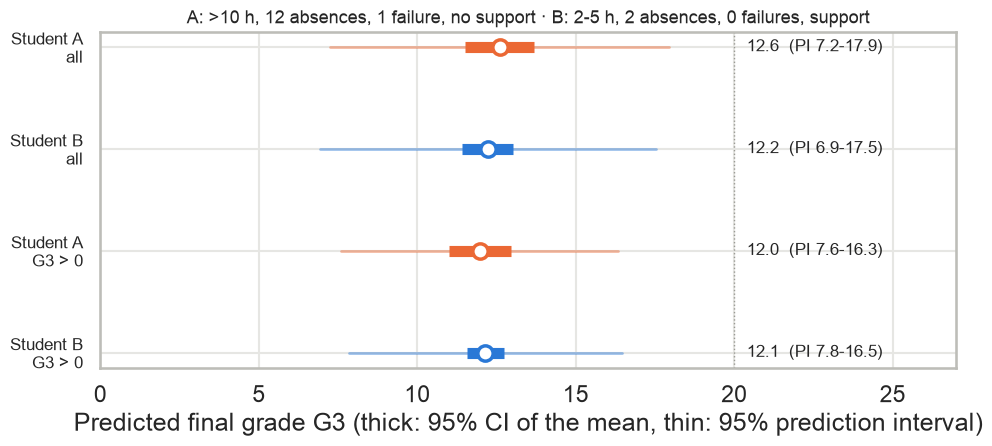

In [14]:
P = preds[preds.model == "M3 + family/social"]
fig, ax = plt.subplots(figsize=(10, 4.8))
ylab = []
for i, (_, r) in enumerate(P.iterrows()):
    c = ORANGE if r.student == "Student A" else BLUE
    ax.plot([r.pi_lo, r.pi_hi], [i, i], color=c, lw=2, alpha=0.45)
    ax.plot([r.ci_lo, r.ci_hi], [i, i], color=c, lw=8, solid_capstyle="butt")
    ax.plot(r.pred, i, "o", color="white", mec=c, mew=2.5, ms=11)
    ax.text(20.4, i, f"{r.pred:.1f}  (PI {r.pi_lo:.1f}-{r.pi_hi:.1f})", va="center", fontsize=12)
    ylab.append(f"{r.student}\n{'all' if r['sample'] == 'all' else 'G3 > 0'}")
ax.set_yticks(range(len(P)), ylab, fontsize=12)
ax.set(xlim=(0, 27), xlabel="Predicted final grade G3 (thick: 95% CI of the mean, thin: 95% prediction interval)",
       title="A: >10 h, 12 absences, 1 failure, no support · B: 2-5 h, 2 absences, 0 failures, support")
ax.title.set_fontsize(13)
ax.axvline(20, color=GREY, ls=":", lw=1)
ax.invert_yaxis()
savefig(fig, "10_profile_predictions")

**Interpretation:** **Surprising result, check before using on a slide.** M3 predicts Student A (10+ h, 12 absences, 1 failure, no support) at 12.6 and Student B (2-5 h, 2 absences, no failures, support) at 12.2 on all students: A is *higher*, though the difference is far inside the uncertainty (95% CIs 11.5-13.7 and 11.4-13.0). Without zero-grade cases they are almost tied (12.0 vs 12.1). The decomposition explains why: the extra study time is worth +0.70, absences -0.21 and the failure -1.42, but the school-support dummy adds +1.30 in A's favour, because in the data supported students score lower (they are supported *because* they are struggling). Hold school support equal and B is ahead by 0.93 points (1.34 without zero-grade cases); in M2, which has no support variable, B is ahead by 1.16 (1.58 without zero-grade cases). Either way the **95% prediction intervals for individuals span about 10 points (roughly 7 to 18)**, so the model cannot tell these two students apart: the honest message is that a profile predicts the average, not the person. If the profile slide is kept, drop school support from the profile definition or say explicitly that it is a reverse-causality marker.

## 9. Pilot check
Automatic comparison with readme section 5. Remember: readme "M2" = M3 here, readme "M3" = M4 here.

In [15]:
L = ladder.set_index(["model", "sample"])
def cv(model, sample, term, what="estimate", spec="numeric"):
    m = MODELS[(model, sample, spec)]
    return {"estimate": m.params[term], "p": m.pvalues[term], "lo": m.conf_int().loc[term, 0],
            "hi": m.conf_int().loc[term, 1]}[what]
M1, M3, M4 = "M1 study time", "M3 + family/social", "M4 + G1, G2"
def simple_log(sample, what):
    m = fit("G3 ~ log_abs", SAMPLES[sample]); return m.params["log_abs"] if what == "b" else m.pvalues["log_abs"]
def inter(sample, what):
    m = fit("G3 ~ studytime * failures + log_abs + C(sex) + C(school)", SAMPLES[sample])
    return m.params["studytime:failures"] if what == "b" else m.pvalues["studytime:failures"]
checks = {
    "M1 b all (0.97)": (L.loc[(M1, "all"), "b"], 0.97), "M1 lo all (0.69)": (L.loc[(M1, "all"), "lo"], 0.69),
    "M1 hi all (1.25)": (L.loc[(M1, "all"), "hi"], 1.25), "M1 R2 all (0.06)": (L.loc[(M1, "all"), "r2"], 0.06),
    "readme-M2 b all (0.42)": (L.loc[(M3, "all"), "b"], 0.42), "readme-M2 lo all (0.17)": (L.loc[(M3, "all"), "lo"], 0.17),
    "readme-M2 hi all (0.66)": (L.loc[(M3, "all"), "hi"], 0.66), "readme-M2 p all (0.001)": (L.loc[(M3, "all"), "p"], 0.001),
    "readme-M2 R2 all (0.34)": (L.loc[(M3, "all"), "r2"], 0.34),
    "readme-M3 b all (0.05)": (L.loc[(M4, "all"), "b"], 0.05), "readme-M3 p all (0.31)": (L.loc[(M4, "all"), "p"], 0.31),
    "readme-M3 R2 all (0.86)": (L.loc[(M4, "all"), "r2"], 0.86),
    "M1 b G3>0 (0.80)": (L.loc[(M1, "G3>0"), "b"], 0.80), "readme-M2 b G3>0 (0.31)": (L.loc[(M3, "G3>0"), "b"], 0.31),
    "readme-M2 p G3>0 (0.009)": (L.loc[(M3, "G3>0"), "p"], 0.009), "readme-M2 R2 G3>0 (0.37)": (L.loc[(M3, "G3>0"), "r2"], 0.37),
    "readme-M3 b G3>0 (0.01)": (L.loc[(M4, "G3>0"), "b"], 0.01), "readme-M3 p G3>0 (0.75)": (L.loc[(M4, "G3>0"), "p"], 0.75),
    "readme-M3 R2 G3>0 (0.89)": (L.loc[(M4, "G3>0"), "r2"], 0.89),
    "failures (-1.42)": (cv(M3, "all", "failures"), -1.42), "higher (+1.81)": (cv(M3, "all", "C(higher)[T.yes]"), 1.81),
    "school MS (-1.31)": (cv(M3, "all", "C(school)[T.MS]"), -1.31), "schoolsup (-1.33)": (cv(M3, "all", "C(schoolsup)[T.yes]"), -1.33),
    "sex M (-0.48)": (cv(M3, "all", "C(sex)[T.M]"), -0.48), "sex M p (0.06)": (cv(M3, "all", "C(sex)[T.M]", "p"), 0.06),
    "log_abs simple all (-0.25)": (simple_log("all", "b"), -0.25), "log_abs simple p all (0.08)": (simple_log("all", "p"), 0.08),
    "log_abs simple G3>0 (-0.59)": (simple_log("G3>0", "b"), -0.59),
    "log_abs readme-M2 all (-0.15)": (cv(M3, "all", "log_abs"), -0.15), "log_abs readme-M2 p all (0.23)": (cv(M3, "all", "log_abs", "p"), 0.23),
    "log_abs readme-M2 G3>0 (-0.45)": (cv(M3, "G3>0", "log_abs"), -0.45),
    "log_abs readme-M3 all (+0.16)": (cv(M4, "all", "log_abs"), 0.16), "log_abs readme-M3 p all (0.02)": (cv(M4, "all", "log_abs", "p"), 0.02),
    "log_abs readme-M3 G3>0 (-0.01)": (cv(M4, "G3>0", "log_abs"), -0.01), "log_abs readme-M3 p G3>0 (0.88)": (cv(M4, "G3>0", "log_abs", "p"), 0.88),
    "interaction G3>0 (-0.52)": (inter("G3>0", "b"), -0.52), "interaction p G3>0 (0.02)": (inter("G3>0", "p"), 0.02),
    "interaction all (-0.20)": (inter("all", "b"), -0.20), "interaction p all (0.52)": (inter("all", "p"), 0.52),
}
chk = pd.DataFrame([{"check": k, "notebook": round(float(v), 4), "pilot": p,
                     "match": abs(float(v) - p) <= 0.006 + 0.005 * abs(p)} for k, (v, p) in checks.items()])
print("all match:", chk.match.all())
chk[~chk.match] if not chk.match.all() else chk

all match: True


,check,notebook,pilot,match
0,M1 b all (0.97),0.9728,0.970,True
1,M1 lo all (0.69),0.6908,0.690,True
2,M1 hi all (1.25),1.2549,1.250,True
3,M1 R2 all (0.06),0.0624,0.060,True
4,readme-M2 b all (0.42),0.4155,0.420,True
5,readme-M2 lo all (0.17),0.1672,0.170,True
6,readme-M2 hi all (0.66),0.6637,0.660,True
7,readme-M2 p all (0.001),0.0010,0.001,True
8,readme-M2 R2 all (0.34),0.3377,0.340,True
9,readme-M3 b all (0.05),0.0534,0.050,True


**Interpretation:** **All 39 pilot numbers from readme section 5 that this notebook covers are reproduced** within rounding (ladder, R², controls coefficients, log-absence coefficients, interaction). Nothing in the pilot is contradicted numerically. Disagreements are with the readme's *narrative*: (1) the log functional form is only preferred without zero-grade cases (section 5); (2) the study-time dummies are jointly non-significant in M3 without zero-grade cases (p = 0.063, section 2); (3) the profile comparison is dominated by the school-support dummy (section 8). Also note the renumbering: readme "M2 + controls" = M3 here, readme "M3 + G1, G2" = M4 here.

## 10. Save the comparison table

In [16]:
out = pd.DataFrame(OUT)
out.to_csv(RES / "regression_comparison.csv", index=False)
print(f"saved results/regression_comparison.csv ({len(out)} rows); sections:", out.section.value_counts().to_dict())
ladder.round(3)

saved results/regression_comparison.csv (120 rows); sections: {'M3 full coefficients': 40, 'ladder (studytime dummies)': 24, 'ladder (numeric studytime)': 14, 'functional form (simple)': 8, 'functional form (in M3)': 8, 'profile prediction': 8, 'interaction (lean (pilot))': 6, 'interaction (full M3 controls)': 6, 'standardised / predicted difference': 6}


,model,sample,b,lo,hi,p,r2,adj_r2,n,k
0,M1 study time,all,0.973,0.691,1.255,0.000,0.062,0.061,649,1
1,M2 + academic/demographic,all,0.447,0.195,0.698,0.000,0.287,0.278,649,8
2,M3 + family/social,all,0.415,0.167,0.664,0.001,0.338,0.317,649,20
3,"M4 + G1, G2",all,0.053,-0.049,0.156,0.307,0.856,0.851,649,22
4,M1 study time,G3>0,0.795,0.542,1.049,0.000,0.060,0.059,634,1
5,M2 + academic/demographic,G3>0,0.334,0.101,0.568,0.005,0.302,0.293,634,8
6,M3 + family/social,G3>0,0.310,0.078,0.543,0.009,0.369,0.348,634,20
7,"M4 + G1, G2",G3>0,0.014,-0.072,0.101,0.747,0.888,0.884,634,22


**Interpretation:** `results/regression_comparison.csv` (long format, one row per model × sample × term, with HC3 SE, 95% CI, p, R², adj R², AIC, n; profile rows also carry the prediction interval). Figures: `08_coefficient_ladder.png`, `09_coefficient_plot_m3.png`, `10_profile_predictions.png`. Headline: studying is associated with about +1 point per category raw, about +0.4 once past failures, ambition and school are held fixed, and about 0 once earlier grades are held fixed. History dominates.